In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import AllChem, DataStructs
import os 

# =====================================================================
# 1. HELPER FUNCTION TO GENERATE MORGAN FINGERPRINTS
# =====================================================================
def get_morgan_fingerprints(smiles_list, radius=2, nBits=1024):
    fps = []
    for smiles in smiles_list:
        try:
            mol = Chem.MolFromSmiles(smiles)
            if mol is not None:
                # Radius=2 corresponds to standard ECFP4 equivalents
                fp = AllChem.GetMorganFingerprintAsBitVect(mol, radius=radius, nBits=nBits)
                fps.append(fp)
        except:
            continue
    return fps

print("--- STEP 1: LOADING DATASETS AND GENERATING RECONSTRUCTED FINGERPRINTS ---")
df_train = pd.read_csv("data/HER2_ChEMBL_prepared_training_set.csv") 
# df_pubchem should contain your 6,025 raw screening structures
df_pubchem = pd.read_csv("data/pubchem_erbb2_screening_set.csv") 

# FIXED: Using your exact column names ('canonical_smiles' and 'ConnectivitySMILES')
fps_train = get_morgan_fingerprints(df_train['canonical_smiles'])
fps_pubchem = get_morgan_fingerprints(df_pubchem['ConnectivitySMILES'])

print(df_train.columns)
print(df_train.shape)

print(df_pubchem.columns)
print(df_pubchem.shape)


--- STEP 1: LOADING DATASETS AND GENERATING RECONSTRUCTED FINGERPRINTS ---


[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerator
[12:52:39] DEPRECATION WARNING: please use MorganGenerat

Index(['molecule_chembl_id', 'canonical_smiles', 'activity_class',
       'binary_outcome'],
      dtype='str')
(3352, 4)
Index(['CID', 'ConnectivitySMILES'], dtype='str')
(4593, 2)


[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerator
[12:52:41] DEPRECATION WARNING: please use MorganGenerat

In [8]:


print(f"Successfully processed {len(fps_train)} ChEMBL training fingerprints and {len(fps_pubchem)} PubChem screening fingerprints.")

# =====================================================================
# 2. BULK PAIRWISE TANIMOTO SIMILARITY CALCULATION
# =====================================================================
print("\n--- STEP 2: CALCULATING PAIRWISE TANIMOTO SIMILARITY MATRIX ---")
tanimoto_scores = []

# Loop through each training molecule and calculate its similarity to all screening structures
for fp_t in fps_train:
    # BulkTanimotoSimilarity processes millions of operations efficiently in memory arrays
    scores = DataStructs.BulkTanimotoSimilarity(fp_t, fps_pubchem)
    tanimoto_scores.extend(scores)

# Calculate your project's specific dataset statistics
mean_similarity = np.mean(tanimoto_scores)
print(f"Calculated Inter-Dataset Mean Tanimoto Score: {mean_similarity:.4f}")


Successfully processed 3352 ChEMBL training fingerprints and 4593 PubChem screening fingerprints.

--- STEP 2: CALCULATING PAIRWISE TANIMOTO SIMILARITY MATRIX ---
Calculated Inter-Dataset Mean Tanimoto Score: 0.1931



--- STEP 3: PLOTTING GRAPH PROFILE DISTRIBUTION ---


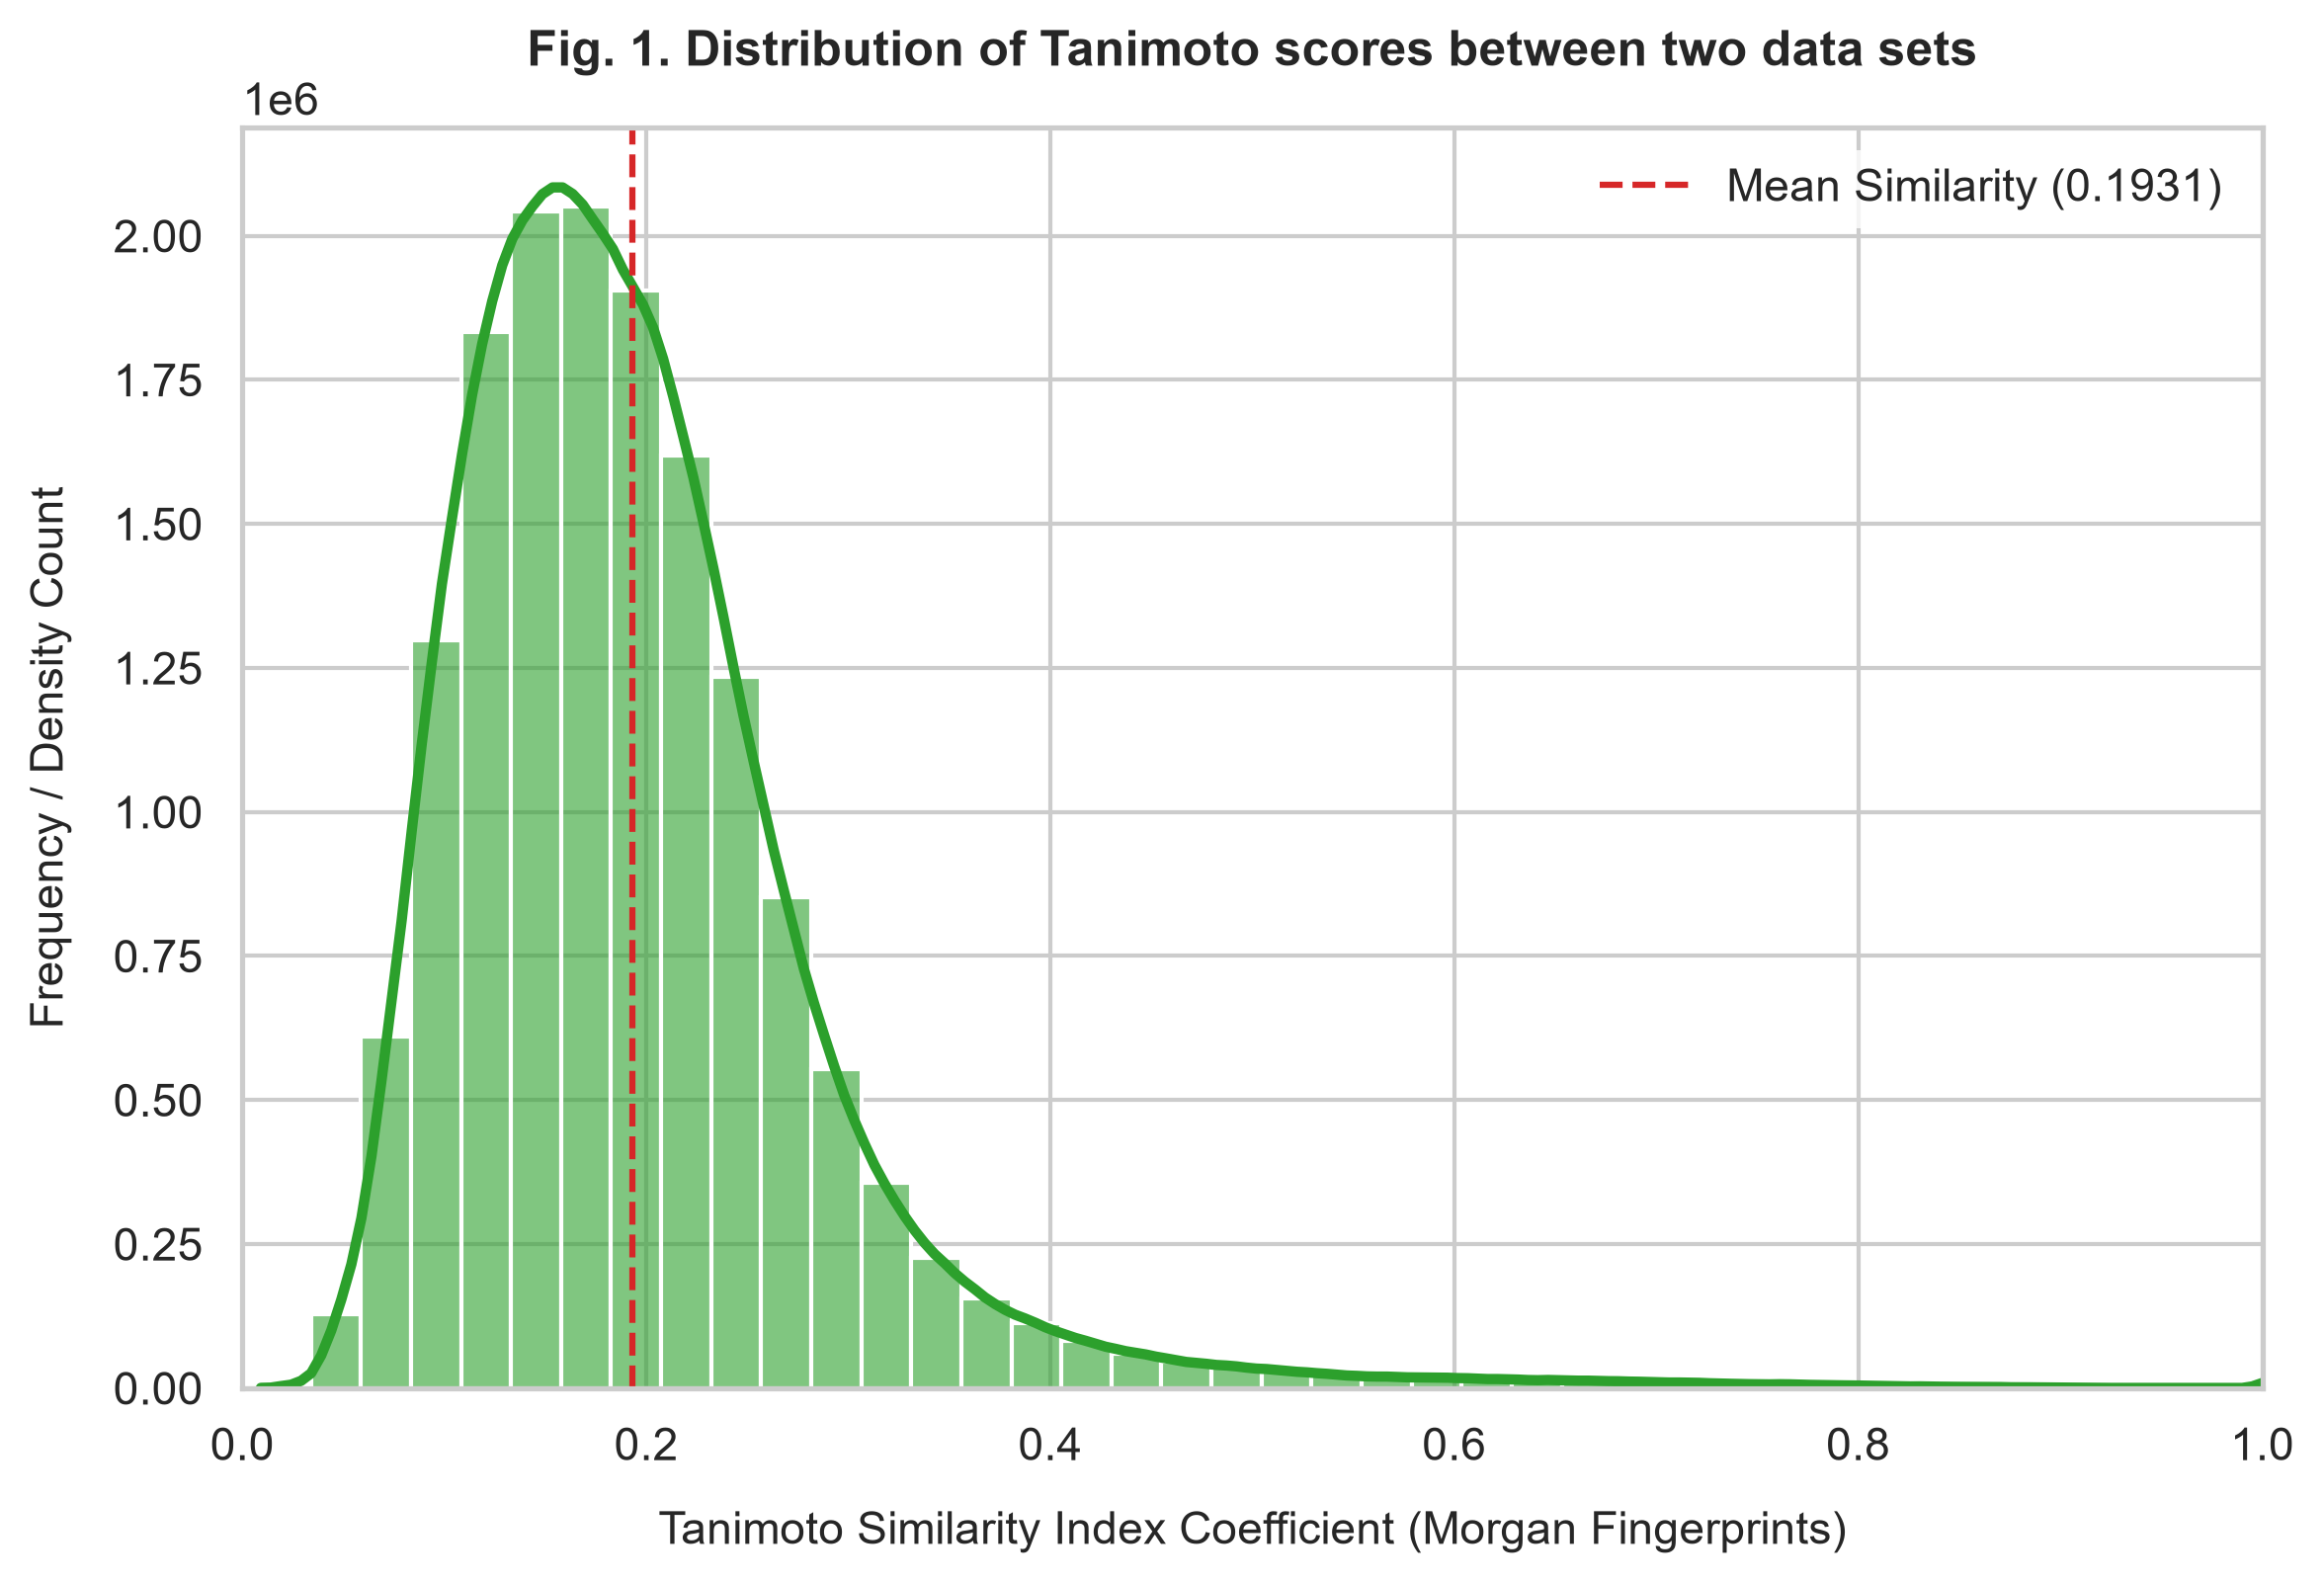

🎉 Figure 1 successfully generated and exported to '/content/data/figure_1_tanimoto_distribution_final.png'!


In [9]:

# =====================================================================
# 3. GRAPHING THE HISTOGRAM DISTRIBUTION (PUBLICATION-READY FIG 1)
# =====================================================================
print("\n--- STEP 3: PLOTTING GRAPH PROFILE DISTRIBUTION ---")
sns.set_theme(style="whitegrid")
plt.figure(figsize=(8, 5.5), dpi=300)

# Build the structural distribution plot with a smooth Kernel Density Estimation (KDE) line
sns.histplot(
    tanimoto_scores, 
    kde=True, 
    color="#2ca02c", # Elegant publication green matching the paper workflow
    bins=40, 
    edgecolor='w',
    linewidth=1.0,
    alpha=0.6,
    line_kws={"linewidth": 2.5, "color": "#1f77b4"} # Blue trend highlight line
)

# Overlay your calculated mathematical mean line
plt.axvline(
    mean_similarity, 
    color='#d62728', 
    linestyle='--', 
    linewidth=1.5, 
    label=f'Mean Similarity ({mean_similarity:.4f})'
)

# Formatting axes labels and scaling parameters
plt.title("Fig. 1. Distribution of Tanimoto scores between two data sets", fontsize=12, pad=15, fontweight='bold')
plt.xlabel("Tanimoto Similarity Index Coefficient (Morgan Fingerprints)", fontsize=11, labelpad=10)
plt.ylabel("Frequency / Density Count", fontsize=11, labelpad=10)

# Bounds checking: Tanimoto ranges strictly between 0 (completely unique) and 1 (identical)
plt.xlim(0.0, 1.0) 
plt.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()

# Export step
output_dir = "/content/data"
os.makedirs(output_dir, exist_ok=True)
output_png = f"{output_dir}/figure_1_tanimoto_distribution_final.png"
plt.savefig(output_png, bbox_inches='tight')
plt.show()

print(f"🎉 Figure 1 successfully generated and exported to '{output_png}'!")